In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import time

## Exercício — Simulação da distribuição normal

Considere a densidade da normal padrão,

$$
f(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2},
$$

e, para $x>0$, utilize como distribuição proposta uma exponencial com taxa $1$,

$$
g(x)=e^{-x}, \qquad x\geq 0.
$$

1. Para aplicar o método de rejeição-aceitação, determine a constante

$$
c=\sup_{x>0}\frac{f(x)}{g(x)}.
$$

Para isso, encontre o ponto de máximo da razão $f(x)/g(x)$ e obtenha a expressão da probabilidade de aceitação

$$
\frac{f(x)}{c\,g(x)}.
$$

In [50]:
c = 2*np.exp(1/2)/np.sqrt(2*np.pi)

In [51]:
print(c)

1.315489246958914


In [52]:
def densidade_normal(x, mi=0, sigma2=1):
    return (2/np.sqrt(2*np.pi*sigma2))*np.exp(-1/(2*sigma2)*(x-mi)**2)

In [53]:
def densidade_exp(x, lamb=1):
    return lamb*np.exp(-x*lamb)

2. A partir do resultado anterior, implemente em Python um algoritmo de rejeição-aceitação para gerar uma amostra de tamanho $n$ da distribuição de $|N(0,1)|$.

In [54]:
amostra = []
n = 100_000

for i in range(n):
    U = np.random.uniform()
    y = (-1)*np.log(np.random.uniform())
    if U < densidade_normal(y)/(c*densidade_exp(y)):
        amostra.append(y)

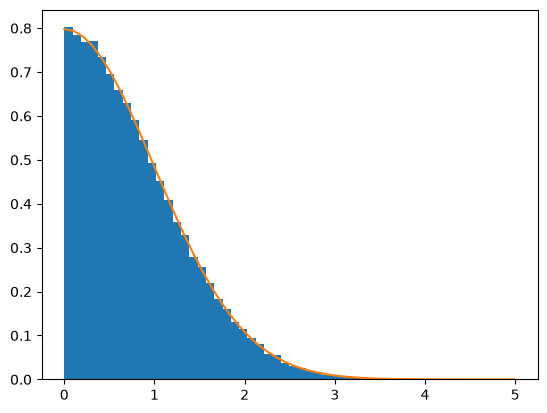

In [55]:
x = np.linspace(0,5)
fx = densidade_normal(x)
plt.hist(amostra, density=True, bins=50)
plt.plot(x,fx)

3. Utilize sinais aleatórios independentes, com probabilidades iguais de serem positivos ou negativos, para transformar essa amostra em uma amostra de

$$
N(0,1).
$$

Gere também uma amostra de mesmo tamanho utilizando `numpy.random.normal` e compare as duas distribuições por meio de histogramas.

In [56]:
amostra_inteira = []
n = 100_000
for i in range(n):
    U = np.random.uniform()
    y = (-1)*np.log(np.random.uniform())
    if U < densidade_normal(y)/(c*densidade_exp(y)):
        if np.random.uniform() < 1/2:
            amostra_inteira.append(y)
        else:
            amostra_inteira.append(-y)

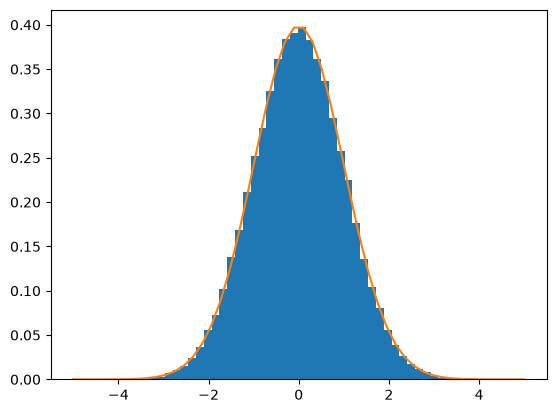

In [71]:
x = np.linspace(-5,5)
fx = densidade_normal(x)/2
plt.hist(amostra_inteira, density=True, bins=50)
plt.plot(x,fx)

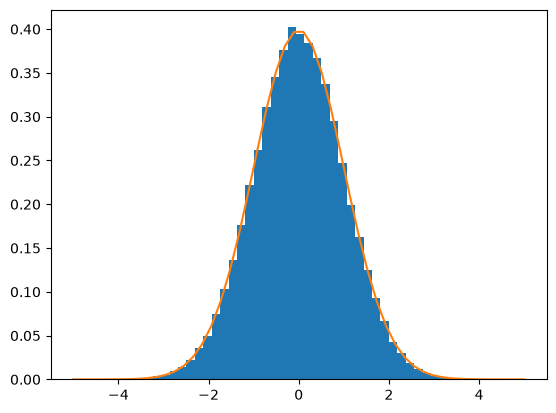

In [70]:
amostra_np = np.random.normal(size=n)
x = np.linspace(-5,5)
fx = densidade_normal(x)/2
plt.hist(amostra_np, density=True, bins=50)
plt.plot(x,fx)

4. Suponha agora que você saiba gerar $Z\sim N(0,1)$. Como você pode utilizar $Z$ para gerar

$$
X\sim N(\mu,\sigma^2)?
$$

Implemente essa transformação para gerar uma amostra de tamanho $n$ de $N(\mu,\sigma^2)$.

In [59]:
mi = 10
sigma2 = 4
normal_generica = mi + np.sqrt(sigma2)*np.array(amostra_inteira)

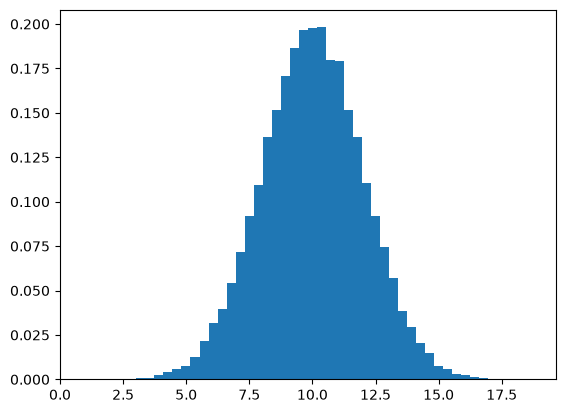

In [60]:
plt.hist(normal_generica, density=True, bins=50)
plt.show()

5. Gere também uma amostra de $N(\mu,\sigma^2)$ utilizando `numpy.random.normal` e compare os histogramas das duas amostras.

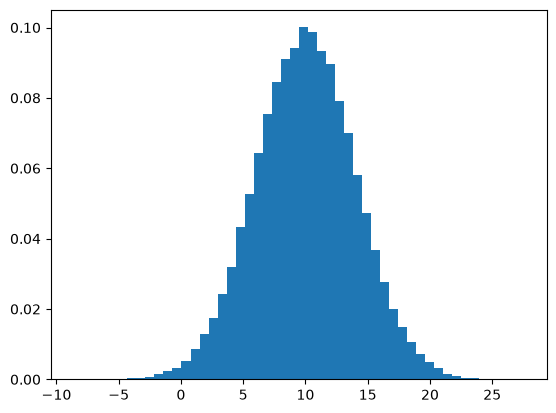

In [61]:
normal_10_4 = np.random.normal(loc=10, scale=4, size=n)
plt.hist(normal_10_4, density=True, bins=50)
plt.show()

6. Durante a simulação, registre o número total de propostas geradas e calcule a taxa empírica de aceitação,

$$
\widehat{p}_{\text{aceitação}}
=
\frac{\text{número de valores aceitos}}
{\text{número total de propostas}}.
$$

Compare esse valor com a taxa teórica de aceitação do método,

$$
p_{\text{aceitação}}=\frac{1}{c},
$$

onde $c$ é a constante obtida anteriormente. Os valores observado e esperado são compatíveis?

In [62]:
amostra_inteira = []
n = 100_000
sucessos = 0
tentativas = 0
for i in range(n):
    U = np.random.uniform()
    y = (-1)*np.log(np.random.uniform())
    if U < densidade_normal(y)/(c*densidade_exp(y)):
        sucessos += 1
        if np.random.uniform() < 1/2:
            amostra_inteira.append(y)
        else:
            amostra_inteira.append(-y)
    tentativas += 1

In [63]:
print(sucessos/tentativas)

0.7612


In [64]:
print(1/c)

0.7601734505331403
